# 04 Model

Features and target for the day-ahead price forecast. Each row is one 5-minute interval. Every feature uses only information available at midnight before that day.

In [1]:
from pathlib import Path

import holidays
import pandas as pd

START = "2024-02-17"
DAY = 288

files = sorted(Path("../data/raw").glob("*.csv"))
prices = (
    pd.concat(pd.read_csv(f, parse_dates=["SETTLEMENTDATE"]) for f in files)
    .set_index("SETTLEMENTDATE")
    .sort_index()[["RRP", "TOTALDEMAND"]]
)

weather = pd.read_csv(
    "../data/processed/weather.csv", parse_dates=["SETTLEMENTDATE"], index_col = "SETTLEMENTDATE"
)
print(prices.shape, weather.shape)

(210528, 2) (179424, 12)


In [2]:
def build_features(prices: pd.DataFrame, weather: pd.DataFrame) -> pd.DataFrame:
    """Build the feature table. Every feature is known at midnight before the trading day"""
    rrp = prices["RRP"]
    demand = prices["TOTALDEMAND"]

    df = pd.DataFrame(index=prices.index)
    df["target"] = rrp

    # Timestamps mark the END of each interval, so subtract 5 minutes to get the start.
    # This puts the 00:00 interval in the day it belongs to.
    interval_start = df.index - pd.Timedelta(minutes=5)
    df["trading_day"] = interval_start.normalize()

    #Calendar
    df["hour"] = interval_start.hour
    df["minute_of_day"] = interval_start.hour * 60 + interval_start.minute
    df["day_of_week"] = df["trading_day"].dt.day_of_week
    df["month"] = df["trading_day"].dt.month
    sa_holidays = holidays.Australia(subdiv="SA", years=range(2023, 2026))
    df["is_holiday"] = df["trading_day"].dt.date.isin(list(sa_holidays.keys())).astype(int)

    #Price and Demand history (at least 1 day old)
    df["price_lag_1d"] = rrp.shift(DAY)
    df["price_lag_7d"] = rrp.shift(7 * DAY)
    df["price_median_7d"] = pd.concat([rrp.shift(k*DAY) for k in range(1,8)], axis=1).median(axis=1)
    df["demand_lag_1d"] = demand.shift(DAY)

    # Yesterday's summary
    daily = pd.DataFrame({
        "prev_day_mean": rrp.groupby(df["trading_day"]).mean(),
        "prev_day_max": rrp.groupby(df["trading_day"]).max(),
        "prev_day_min": rrp.groupby(df["trading_day"]).min(),
        "prev_day_spikes": (rrp > 300).groupby(df["trading_day"]).sum(),
    }).shift(1)  # shift by one day, so each day sees the PREVIOUS day's numbers
    df = df.join(daily, on="trading_day")

    # Weather forecasts
    df = df.join(weather)
    df["wind_mean"] = df[["snowtown_wind_speed_100m", "hallett_wind_speed_100m"]].mean(axis=1)

    return df.drop(columns="trading_day")

In [3]:
features = build_features(prices, weather).loc[f"{START} 00:05":]

assert features.isna().sum().sum() == 0, features.isna().sum()[lambda s: s>0]
print(features.shape)
features.head()

(179424, 27)


,target,hour,minute_of_day,day_of_week,month,is_holiday,price_lag_1d,price_lag_7d,price_median_7d,demand_lag_1d,...,adelaide_cloud_cover,snowtown_temperature_2m,snowtown_wind_speed_100m,snowtown_shortwave_radiation,snowtown_cloud_cover,hallett_temperature_2m,hallett_wind_speed_100m,hallett_shortwave_radiation,hallett_cloud_cover,wind_mean
SETTLEMENTDATE,,,,,,,,,,,,,,,,,,,,,
2024-02-17 00:05:00,93.86,0,0,5,2,0,56.86,18.88,56.86,1415.19,...,0.0,18.591667,16.141667,0.0,0.0,18.791667,22.483333,0.0,0.0,19.3125
2024-02-17 00:10:00,95.50,0,5,5,2,0,66.28,8.89,66.18,1423.11,...,0.0,18.483333,16.083333,0.0,0.0,18.683333,22.366667,0.0,0.0,19.2250
2024-02-17 00:15:00,94.98,0,10,5,2,0,57.16,8.89,65.54,1418.65,...,0.0,18.375000,16.025000,0.0,0.0,18.575000,22.250000,0.0,0.0,19.1375
2024-02-17 00:20:00,96.93,0,15,5,2,0,62.33,8.75,62.33,1425.38,...,0.0,18.266667,15.966667,0.0,0.0,18.466667,22.133333,0.0,0.0,19.0500
2024-02-17 00:25:00,96.25,0,20,5,2,0,57.75,7.77,63.72,1423.78,...,0.0,18.158333,15.908333,0.0,0.0,18.358333,22.016667,0.0,0.0,18.9625


In [4]:
t = pd.Timestamp("2025-03-12 18:00")
print("price_lag_1d:", features.loc[t, "price_lag_1d"], "| actual 24h earlier:", prices.loc[t - pd.Timedelta(days=1), "RRP"])
print("price_lag_7d:", features.loc[t, "price_lag_7d"], "| actual 7d earlier:", prices.loc[t - pd.Timedelta(days=7), "RRP"])
print("prev_day_max:", features.loc[t, "prev_day_max"], "| actual max on 11 Mar:", prices.loc["2025-03-11 00:05":"2025-03-12 00:00", "RRP"].max())

price_lag_1d: 164.02 | actual 24h earlier: 164.02
price_lag_7d: -31.27 | actual 7d earlier: -31.27
prev_day_max: 349.98 | actual max on 11 Mar: 349.98


In [5]:
FEATURES = [c for c in features.columns if c != "target"]

idx = features.index
train = features[idx <= "2025-05-01 00:00"]
val = features[(idx > "2025-05-01 00:00") & (idx <= "2025-08-01 00:00")]
test = features[idx > "2025-08-01 00:00"]

for name, part in [("train", train), ("val", val), ("test", test)]:
    print(f"{name:5} {part.index.min()} to {part.index.max()}  {len(part):,} rows")

train 2024-02-17 00:05:00 to 2025-05-01 00:00:00  126,432 rows
val   2025-05-01 00:05:00 to 2025-08-01 00:00:00  26,496 rows
test  2025-08-01 00:05:00 to 2025-11-01 00:00:00  26,496 rows


In [6]:
import lightgbm as lgb

model = lgb.LGBMRegressor(
    objective="l1",          # optimise MAE directly, so spikes don't dominate
    n_estimators=2000,       # upper limit, early stopping picks the real number
    learning_rate=0.05,
    num_leaves=63,
    min_child_samples=100,   # each leaf needs 100+ intervals, which reduces overfitting
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    random_state=42,
    verbose=-1,
)

model.fit(
    train[FEATURES], train["target"],
    eval_X=val[FEATURES],
    eval_y=val["target"],
    eval_metric="l1",
    callbacks=[lgb.early_stopping(100), lgb.log_evaluation(200)],
)

Training until validation scores don't improve for 100 rounds
[200]	valid_0's l1: 106.358
Early stopping, best iteration is:
[234]	valid_0's l1: 106.324


,num_leaves,63
,learning_rate,0.05
,n_estimators,2000
,objective,'l1'
,min_child_samples,100
,subsample,0.8
,subsample_freq,1
,colsample_bytree,0.8
,random_state,42
,verbose,-1
,boosting_type,'gbdt'


In [7]:
def evaluate(actual: pd.Series, forecast: pd.Series, spike_threshold:float = 300) -> dict:
    """ MAE overall, on normal intervals, and on spikes. """
    mask = forecast.notna()
    actual, forecast = actual[mask], forecast[mask]
    error = (actual - forecast).abs()
    spike = actual > spike_threshold
    return {
        "MAE": error.mean(),
        "MAE normal": error[~spike].mean(),
        "MAE spike": error[spike].mean(),
        "n spikes": int(spike.sum()),
    }

In [8]:
val_pred = pd.Series(model.predict(val[FEATURES]), index=val.index)

val_results = pd.DataFrame({
    "median_7d baseline": evaluate(val["target"], val["price_median_7d"]),
    "LightGBM": evaluate(val["target"], val_pred),
}).T.round(1)
val_results["n spikes"] = val_results["n spikes"].astype(int)
val_results

,MAE,MAE normal,MAE spike,n spikes
median_7d baseline,144.2,79.7,1503.4,1201
LightGBM,106.3,43.4,1431.7,1201


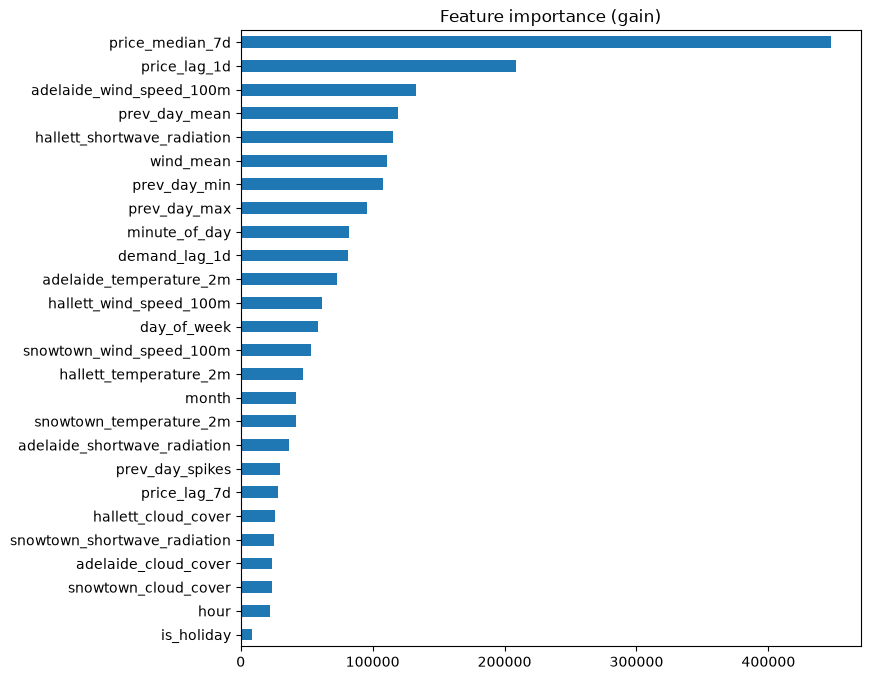

In [9]:
importance = pd.Series(
    model.booster_.feature_importance(importance_type="gain"), index=FEATURES
).sort_values()
importance.plot(kind="barh", figsize=(8, 8), title="Feature importance (gain)");

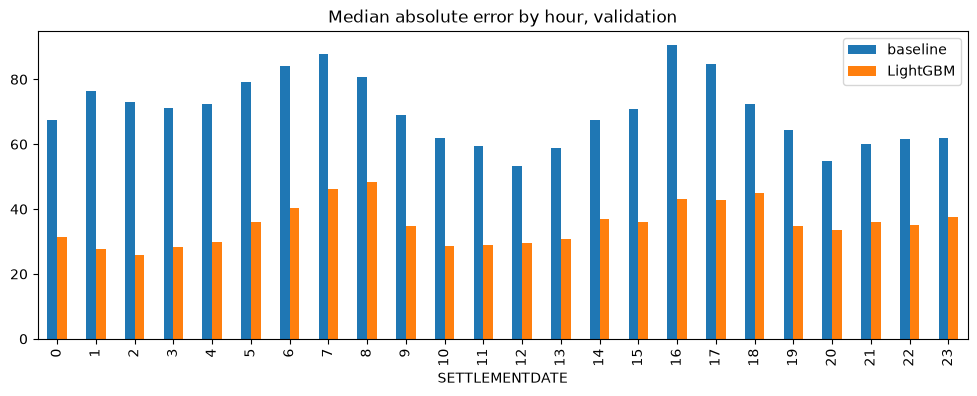

In [10]:
err = pd.DataFrame({
    "baseline": (val["target"] - val["price_median_7d"]).abs(),
    "LightGBM": (val["target"] - val_pred).abs(),
})
err.groupby(err.index.hour).median().plot(kind="bar", figsize=(12, 4), title="Median absolute error by hour, validation");

In [11]:
test_pred = pd.Series(model.predict(test[FEATURES]), index=test.index)

test_results = pd.DataFrame({
    "median_7d baseline": evaluate(test["target"], test["price_median_7d"]),
    "LightGBM": evaluate(test["target"], test_pred),
}).T.round(1)
test_results["n spikes"] = test_results["n spikes"].astype(int)
test_results

,MAE,MAE normal,MAE spike,n spikes
median_7d baseline,58.4,55.3,370.5,259
LightGBM,38.8,36.1,307.8,259


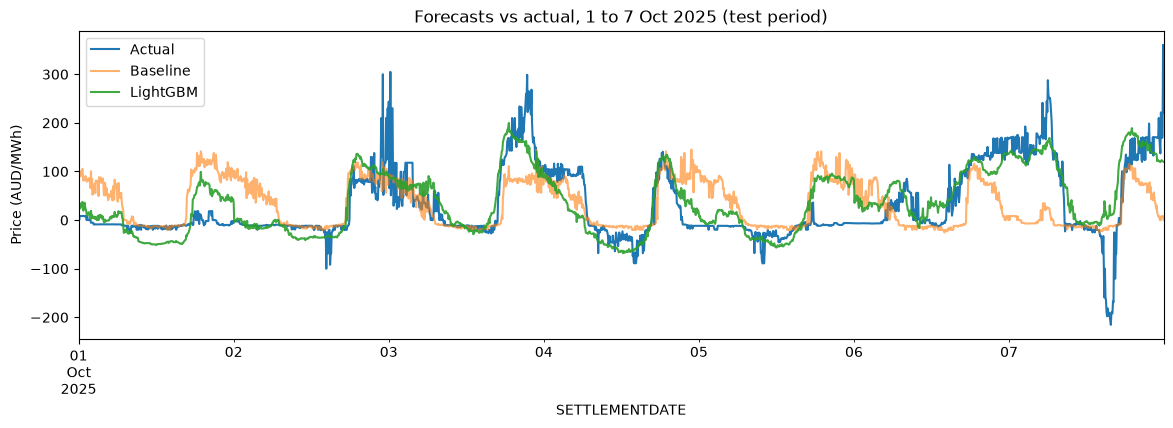

In [12]:
week = slice("2025-10-01", "2025-10-07")
ax = test.loc[week, "target"].plot(figsize=(14, 4), label="Actual")
test.loc[week, "price_median_7d"].plot(ax=ax, label="Baseline", alpha=0.6)
test_pred.loc[week].plot(ax=ax, label="LightGBM", alpha=0.9)
ax.set_ylabel("Price (AUD/MWh)")
ax.set_title("Forecasts vs actual, 1 to 7 Oct 2025 (test period)")
ax.legend();

## Results

*MAE in AUD/MWh. Test period 1 Aug to 31 Oct 2025, untouched until this point.*

| | Baseline (median_7d) | LightGBM | Improvement |
|---|---|---|---|
| MAE overall | 58.4 | 38.8 | 34% |
| MAE normal | 55.3 | 36.1 | 35% |
| MAE spike | 370.5 | 307.8 | 17% |

**Finding:** LightGBM with day-ahead weather forecasts beats the baseline by 34% on the test period, past my target of under 50.

**Evidence:**
- On validation (May to Jul 2025), it cut the error on normal intervals almost in half (79.7 to 43.4).
- The typical error dropped at every hour of the day. The biggest remaining errors are the morning and evening ramps, when prices change fastest.
- The baselines (7-day median, yesterday) are the most important features, with wind, solar and temperature next. The model starts from the usual daily shape and adjusts it with the weather.
- In the first week of October, it correctly predicted the low windy evenings (Oct 1 and Oct 5) that the baseline got wrong.

**Limitations:**
- Spikes are still badly predicted. The L1 objective aims for the typical price, so it rarely predicts a spike. On the validation period, spikes made up roughly 60% of the remaining error.
- Validation was a winter period and test was spring, so I haven't tested it on a summer with heatwaves.
- The day-ahead weather forecasts come from one archive, starting Feb 2024, so I only have about 14 months of training data.

**Ideas for later:**
- A separate model to predict the chance of a spike, which could matter more to the battery than the exact price
- Retraining on train plus validation before forecasting, to include the most recent winter
- More weather locations, and AEMO's own demand forecasts as features